### Paso 0: Importación de Librerías y Configuración del Entorno

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Estilo visual minimalista para los gráficos finales
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("✅ Entorno analítico configurado correctamente.")


✅ Entorno analítico configurado correctamente.


### Paso 1: Generación In-Memory de las Fuentes de Datos Heterogéneas

In [2]:
# Fijar semilla para reproducibilidad
np.random.seed(42)
n_records = 500

# ----------------------------------------------------
# ORIGEN 1: CSV Plano - Exportación de Meta Ads
# ----------------------------------------------------
fechas = [datetime(2026, 10, 1) + timedelta(days=int(i)) for i in np.random.randint(0, 30, n_records)]
canales_meta = np.random.choice(['Facebook Ads', 'Instagram Ads'], size=n_records, p=[0.55, 0.45])
campanas = np.random.choice(['Posgrados_Maestria_2026', 'Diplomado_IA_Comunicaciones', 'Branding_Anahuac_Autumn'], size=n_records)

gasto_usd = np.round(np.random.uniform(15.0, 150.0, n_records), 2)
impresiones = np.random.randint(500, 8000, n_records)
clics = np.int32(impresiones * np.random.uniform(0.015, 0.055, n_records))

df_meta_ads = pd.DataFrame({
    'ad_id': [f"META_{1000 + i}" for i in range(n_records)],
    'fecha_anuncio': [f.strftime('%Y-%m-%d') for f in fechas],
    'plataforma_pauta': canales_meta,
    'nombre_campana': campanas,
    'gasto_inversion_usd': gasto_usd,
    'impresiones_servidas': impresiones,
    'clics_registrados': clics
})

df_meta_ads.to_csv('archivos_meta_ads.csv', index=False)
print("📄 Archivo 'archivos_meta_ads.csv' generado exitosamente.")

# ----------------------------------------------------
# ORIGEN 2: JSON Semiestructurado - Google Analytics Events
# ----------------------------------------------------
ga_events = []
dispositivos = ['Mobile', 'Desktop', 'Tablet']
fuentes_ga = ['Facebook Ads', 'Instagram Ads', 'Google Search', 'Organic Direct']

for i in range(n_records):
    event_doc = {
        "event_id": f"GA_EVT_{5000 + i}",
        "timestamp": (datetime(2026, 10, 1) + timedelta(days=int(np.random.randint(0, 30)), hours=int(np.random.randint(0, 23)))).isoformat(),
        "user_pseudo_id": f"USR_{np.random.randint(100, 300):04d}",
        "traffic_source": {
            "source_medium": np.random.choice(fuentes_ga, p=[0.35, 0.35, 0.20, 0.10]),
            "campaign_name": np.random.choice(campanas)
        },
        "device_info": {
            "category": np.random.choice(dispositivos, p=[0.65, 0.30, 0.05]),
            "browser": np.random.choice(['Chrome', 'Safari', 'Firefox'])
        },
        "metrics": {
            "session_duration_sec": int(np.random.exponential(scale=120)),
            "pages_viewed": int(np.random.randint(1, 8)),
            "conversion_flag": int(np.random.choice([0, 1], p=[0.82, 0.18]))
        }
    }
    ga_events.append(event_doc)

with open('google_analytics_events.json', 'w', encoding='utf-8') as f:
    json.dump(ga_events, f, indent=2, ensure_ascii=False)

print("🌐 Archivo 'google_analytics_events.json' generado exitosamente.")

# ----------------------------------------------------
# ORIGEN 3: Base de Datos Relacional SQLite - CRM de Ventas
# ----------------------------------------------------
conn_crm = sqlite3.connect('crm_ventas.sqlite')
cursor = conn_crm.cursor()

cursor.execute("DROP TABLE IF EXISTS crm_leads")
cursor.execute('''CREATE TABLE crm_leads (
    lead_id TEXT PRIMARY KEY,
    user_pseudo_id TEXT,
    fecha_registro TEXT,
    estado_conversion TEXT,
    monto_inscripcion_mxn REAL
)''')

crm_rows = []
for i in range(250):
    user_id = f"USR_{np.random.randint(100, 300):04d}"
    fecha_reg = (datetime(2026, 10, 1) + timedelta(days=int(np.random.randint(0, 30)))).strftime('%Y-%m-%d')
    estado = np.random.choice(['Inscrito', 'En Seguimiento', 'Descartado'], p=[0.25, 0.45, 0.30])
    monto = 18500.0 if estado == 'Inscrito' else 0.0
    crm_rows.append((f"LEAD_{9000 + i}", user_id, fecha_reg, estado, monto))

cursor.executemany("INSERT INTO crm_leads VALUES (?, ?, ?, ?, ?)", crm_rows)
conn_crm.commit()
conn_crm.close()

print("🗄️ Base de datos 'crm_ventas.sqlite' generada exitosamente.")


📄 Archivo 'archivos_meta_ads.csv' generado exitosamente.
🌐 Archivo 'google_analytics_events.json' generado exitosamente.
🗄️ Base de datos 'crm_ventas.sqlite' generada exitosamente.


### Paso 2: Fase E (Extracción de Datos Heterogéneos)

In [3]:
# 1. Extracción de CSV (Meta Ads)
df_meta = pd.read_csv('archivos_meta_ads.csv')
print(f"✅ Ingestados {len(df_meta)} registros desde Meta Ads (CSV).")

# 2. Extracción de JSON (Google Analytics)
with open('google_analytics_events.json', 'r', encoding='utf-8') as f:
    raw_json = json.load(f)

# Desanidado de JSON estructurado con json_normalize
df_ga = pd.json_normalize(raw_json)
print(f"✅ Ingestados {len(df_ga)} eventos desanidados desde Google Analytics (JSON).")

# 3. Extracción de SQL (CRM de Ventas)
conn_crm = sqlite3.connect('crm_ventas.sqlite')
df_crm = pd.read_sql_query("SELECT * FROM crm_leads", conn_crm)
conn_crm.close()
print(f"✅ Ingestados {len(df_crm)} registros de clientes desde el CRM (SQLite).")


✅ Ingestados 500 registros desde Meta Ads (CSV).
✅ Ingestados 500 eventos desanidados desde Google Analytics (JSON).
✅ Ingestados 250 registros de clientes desde el CRM (SQLite).


### Paso 3: Fase T (Transformación, Limpieza y Estandarización)

In [4]:
# A. Transformación de Meta Ads (CSV)
df_meta['gasto_inversion_mxn'] = np.round(df_meta['gasto_inversion_usd'] * 18.50, 2)
df_meta['fecha'] = pd.to_datetime(df_meta['fecha_anuncio']).dt.strftime('%Y-%m-%d')
df_meta.rename(columns={
    'plataforma_pauta': 'canal_origen',
    'nombre_campana': 'campana'
}, inplace=True)

# B. Transformación de Google Analytics (JSON)
df_ga.rename(columns={
    'traffic_source.source_medium': 'canal_origen',
    'traffic_source.campaign_name': 'campana',
    'device_info.category': 'dispositivo',
    'metrics.session_duration_sec': 'duracion_sesion_seg',
    'metrics.pages_viewed': 'paginas_vistas',
    'metrics.conversion_flag': 'conversion_web'
}, inplace=True)

df_ga['fecha'] = pd.to_datetime(df_ga['timestamp']).dt.strftime('%Y-%m-%d')

# C. Transformación de CRM (SQL)
df_crm['fecha'] = pd.to_datetime(df_crm['fecha_registro']).dt.strftime('%Y-%m-%d')
df_crm_inscritos = df_crm[df_crm['estado_conversion'] == 'Inscrito'].copy()

print("🧹 Transformaciones básicas finalizadas. Muestra de Meta Ads en MXN:")
print(df_meta[['ad_id', 'fecha', 'canal_origen', 'gasto_inversion_mxn']].head(3))


🧹 Transformaciones básicas finalizadas. Muestra de Meta Ads en MXN:
       ad_id       fecha  canal_origen  gasto_inversion_mxn
0  META_1000  2026-10-07  Facebook Ads              2352.09
1  META_1001  2026-10-20  Facebook Ads               578.12
2  META_1002  2026-10-29  Facebook Ads               394.79


C:\Users\pdani\AppData\Local\Temp\ipykernel_3232\1606111742.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_meta.rename(columns={
C:\Users\pdani\AppData\Local\Temp\ipykernel_3232\1606111742.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_ga.rename(columns={


### Paso 4: Fase L (Construcción del Data Mart y Modelo en Estrella)

In [5]:
# Conexión al nuevo Almacén de Datos (Data Mart)
conn_dw = sqlite3.connect('almacen_datos_marketing.db')
cursor_dw = conn_dw.cursor()

# 1. Crear Dim_Canal
canales_unicos = pd.DataFrame({
    'canal_id': [1, 2, 3, 4],
    'nombre_canal': ['Facebook Ads', 'Instagram Ads', 'Google Search', 'Organic Direct']
})
canales_unicos.to_sql('Dim_Canal', conn_dw, if_exists='replace', index=False)

# 2. Crear Dim_Campana
campanas_unicas = pd.DataFrame({
    'campana_id': [101, 102, 103],
    'nombre_campana': ['Posgrados_Maestria_2026', 'Diplomado_IA_Comunicaciones', 'Branding_Anahuac_Autumn']
})
campanas_unicas.to_sql('Dim_Campana', conn_dw, if_exists='replace', index=False)

# 3. Crear Dim_Dispositivo
dispositivos_unicos = pd.DataFrame({
    'dispositivo_id': [1, 2, 3],
    'nombre_dispositivo': ['Mobile', 'Desktop', 'Tablet']
})
dispositivos_unicos.to_sql('Dim_Dispositivo', conn_dw, if_exists='replace', index=False)

# 4. Consolidación de Hechos (Fact Table) por Fecha, Canal y Campaña
meta_agg = df_meta.groupby(['fecha', 'canal_origen', 'campana']).agg(
    gasto_total_mxn=('gasto_inversion_mxn', 'sum'),
    impresiones_totales=('impresiones_servidas', 'sum'),
    clics_totales=('clics_registrados', 'sum')
).reset_index()

ga_agg = df_ga.groupby(['fecha', 'canal_origen', 'campana']).agg(
    sesiones_totales=('event_id', 'count'),
    conversiones_web_totales=('conversion_web', 'sum')
).reset_index()

# Unir Hechos de Pauta y Web mediante Outer Join
df_fact = pd.merge(meta_agg, ga_agg, on=['fecha', 'canal_origen', 'campana'], how='outer').fillna(0)

# Mapear llaves foráneas (Foreign Keys)
df_fact = df_fact.merge(canales_unicos, left_on='canal_origen', right_on='nombre_canal', how='left')
df_fact = df_fact.merge(campanas_unicas, left_on='campana', right_on='nombre_campana', how='left')

# Seleccionar y reordenar columnas finales para la Tabla de Hechos
df_fact_final = df_fact[[
    'fecha', 'canal_id', 'campana_id', 
    'gasto_total_mxn', 'impresiones_totales', 'clics_totales', 
    'sesiones_totales', 'conversiones_web_totales'
]].copy()

# Guardar Tabla de Hechos en SQLite
df_fact_final.to_sql('Fact_Inversion_Conversion', conn_dw, if_exists='replace', index=False)

print("⭐ Modelo en Estrella (Star Schema) construido e ingresado con éxito en 'almacen_datos_marketing.db'.")


⭐ Modelo en Estrella (Star Schema) construido e ingresado con éxito en 'almacen_datos_marketing.db'.


### Paso 5: Consultas Analíticas OLAP (Cálculo de CAC y ROAS)

In [6]:
# Consulta OLAP: Rendimiento y Atribución Multicanal
query_olap = '''SELECT 
    c.nombre_canal AS Canal,
    p.nombre_campana AS Campana,
    ROUND(SUM(f.gasto_total_mxn), 2) AS Gasto_Total_MXN,
    SUM(f.clics_totales) AS Clics_Totales,
    SUM(f.conversiones_web_totales) AS Conversiones_Web,
    CASE 
        WHEN SUM(f.conversiones_web_totales) > 0 
        THEN ROUND(SUM(f.gasto_total_mxn) / SUM(f.conversiones_web_totales), 2)
        ELSE 0 
    END AS CAC_Estimado_MXN
FROM Fact_Inversion_Conversion f
JOIN Dim_Canal c ON f.canal_id = c.canal_id
JOIN Dim_Campana p ON f.campana_id = p.campana_id
GROUP BY c.nombre_canal, p.nombre_campana
ORDER BY Gasto_Total_MXN DESC;'''

df_resultado_olap = pd.read_sql_query(query_olap, conn_dw)
conn_dw.close()

print("📊 Tabla Resultante de la Consulta OLAP de Atribución:")
print(df_resultado_olap.to_string(index=False))


📊 Tabla Resultante de la Consulta OLAP de Atribución:
         Canal                     Campana  Gasto_Total_MXN  Clics_Totales  Conversiones_Web  CAC_Estimado_MXN
  Facebook Ads     Branding_Anahuac_Autumn        154317.20        14314.0              15.0          10287.81
  Facebook Ads Diplomado_IA_Comunicaciones        146366.10        14480.0               6.0          24394.35
  Facebook Ads     Posgrados_Maestria_2026        135055.59        12305.0              15.0           9003.71
 Instagram Ads     Branding_Anahuac_Autumn        125458.67        12420.0               9.0          13939.85
 Instagram Ads     Posgrados_Maestria_2026        109541.30        12291.0              10.0          10954.13
 Instagram Ads Diplomado_IA_Comunicaciones         96855.45         9187.0               9.0          10761.72
 Google Search     Branding_Anahuac_Autumn             0.00            0.0               8.0              0.00
 Google Search Diplomado_IA_Comunicaciones             0.0

### Paso 6: Visualización de Indicadores de Negocio

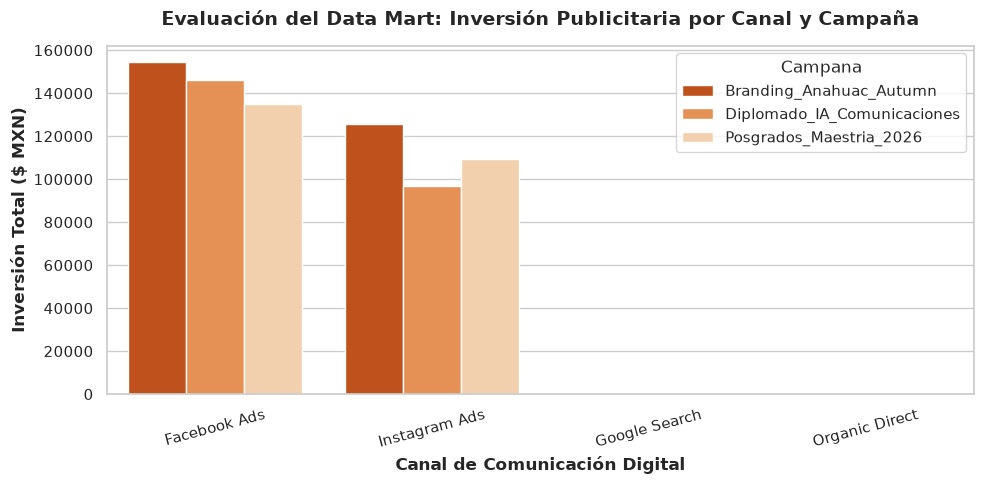

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Gráfico de barras: Gasto Total por Canal
sns.barplot(data=df_resultado_olap, x='Canal', y='Gasto_Total_MXN', hue='Campana', ax=ax1, palette='Oranges_r')
ax1.set_title('Evaluación del Data Mart: Inversión Publicitaria por Canal y Campaña', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Inversión Total ($ MXN)', fontweight='bold')
ax1.set_xlabel('Canal de Comunicación Digital', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
